## <b>PS4 : Neural Networks</b>  
Name : <b>ORIAS, MARK JOSEPH C.</b>       
Section : <b>BSCS 2A</b>

#### <b>Importing the necessary libraries</b>

In [162]:
#!pip install tensorflow
#!pip install pydot
#!pip3 install graphviz

import csv
import matplotlib.pyplot as plt

import tensorflow as tf
import pandas as pd
import numpy as np
import seaborn as sns
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from keras.utils import plot_model
from sklearn.metrics import confusion_matrix

#### <b>Loading the Dataset & Preprocessing</b>

Importing the 'car_evaluation.csv' dataset from the UC Irvine Machine Learning Repository

In [163]:
# Read data in from file
data = pd.read_csv('car-evaluation.csv', delimiter=',')

In [164]:
data.describe()

,vhigh,vhigh.1,2,2.1,small,low,unacc
count,1727,1727,1727,1727,1727,1727,1727
unique,4,4,4,3,3,3,4
top,high,high,3,4,med,med,unacc
freq,432,432,432,576,576,576,1209


**Attribute Information:**

**Class Values:**

> unacc, acc, good, vgood

**Attributes:**

>buying: vhigh, high, med, low.

>maint: vhigh, high, med, low.

>doors: 2, 3, 4, 5more.

>persons: 2, 4, more.

>lug_boot: small, med, big.

>safety: low, med, high.

#### <b>Encoding</b>
Encoding the data. Making categorical variables numeric

In [165]:
le = LabelEncoder()
data = data.apply(le.fit_transform)

#### <b>Splitting Dataset into Features and Target</b>

Separating the dataset into features (X) and the target variable (y) <br>

- X contains the features columns. <br>
- y contains the encoded class labels.

In [166]:
X = data.iloc[:, 0:6]
y = data.iloc[:, -1]

In [167]:
X

,vhigh,vhigh.1,2,2.1,small,low
0,3,3,0,0,2,2
1,3,3,0,0,2,0
2,3,3,0,0,1,1
3,3,3,0,0,1,2
4,3,3,0,0,1,0
...,...,...,...,...,...,...
1722,1,1,3,2,1,2
1723,1,1,3,2,1,0
1724,1,1,3,2,0,1
1725,1,1,3,2,0,2


In [168]:
y

0       2
1       2
2       2
3       2
4       2
       ..
1722    1
1723    3
1724    2
1725    1
1726    3
Name: unacc, Length: 1727, dtype: int32

#### <b>Train-Test Split</b>

Splitting the dataset into training and testing sets.

80% of the data is used for training, and 20% is used for testing.

In [169]:
# Separate data into training and testing groups

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42) 

In [170]:
X_train.shape

(1381, 6)

In [171]:
X_test.shape

(346, 6)

#### <b>Standardizing Features</b>

Normalizing the feature values to achieve a mean of 0 and a standard deviation of 1 is essential for neural networks. This process ensures that all features are equally influential in the model's performance.

In [172]:
#Scale the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)  

#### <b>Neural Network Model</b>

The model has one hidden layer with 10 neurons and ReLU activation.

The output layer has 4 neurons (one for each class) with softmax activation.

Early stopping (see the training step below) is used to limit overfitting.

In [173]:
# Create a neural network
model = tf.keras.models.Sequential()

# Add a hidden layer with 10 units, with ReLU activation
model.add(tf.keras.layers.Dense(10, input_shape=(6,), activation="relu"))

# Add output layer with 4 units (one per class), with softmax activation
model.add(tf.keras.layers.Dense(4, activation="softmax"))

#### <b>Model Summary</b>

This displays the summary of the model including the number of parameters each layer.

In [174]:
#Show Model Summary

model.summary()

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_17 (Dense)            (None, 10)                70        
                                                                 
 dense_18 (Dense)            (None, 4)                 44        
                                                                 
Total params: 114
Trainable params: 114
Non-trainable params: 0
_________________________________________________________________


In [175]:
try:
    plot_model(model, to_file='/tmp/model.png', show_shapes=True,)
except ImportError as e:  # pydot / graphviz are optional
    print(e)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


#### <b>Compiling and Training the Model</b>
The neural network is compiled using the ***Adam optimizer*** with a ***learning rate of 0.01***, the ***sparse_categorical_crossentropy*** loss function for integer-labeled classification, and accuracy as the evaluation metric. To prevent overfitting, ***early stopping is applied***, which monitors the training loss and halts training if no improvement occurs for ***10 consecutive epochs***, while restoring the best model weights. The model is trained on the training data for up to ***50 epochs with a batch size of 17***, and the training history is stored for analysis.

In [176]:
# Compile the neural network
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#Regularization I: early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)


# Train the model
history = model.fit(X_train, 
          y_train, 
          epochs=50,
          batch_size=17,
          callbacks=[early_stopping])

Epoch 1/50
82/82 [==============================] - 1s 7ms/step - loss: 0.9313 - accuracy: 0.6169
Epoch 2/50
82/82 [==============================] - 1s 7ms/step - loss: 0.6603 - accuracy: 0.6944
Epoch 3/50
82/82 [==============================] - 1s 6ms/step - loss: 0.5970 - accuracy: 0.7227
Epoch 4/50
82/82 [==============================] - 0s 6ms/step - loss: 0.5447 - accuracy: 0.7509
Epoch 5/50
82/82 [==============================] - 0s 6ms/step - loss: 0.5139 - accuracy: 0.7668
Epoch 6/50
82/82 [==============================] - 1s 7ms/step - loss: 0.4698 - accuracy: 0.7734
Epoch 7/50
82/82 [==============================] - 0s 5ms/step - loss: 0.4325 - accuracy: 0.8139
Epoch 8/50
82/82 [==============================] - 0s 5ms/step - loss: 0.4048 - accuracy: 0.8255
Epoch 9/50
82/82 [==============================] - 0s 5ms/step - loss: 0.3785 - accuracy: 0.8284
Epoch 10/50
82/82 [==============================] - 0s 5ms/step - loss: 0.3726 - accuracy: 0.8436
Epoch 11/50
82/82 [

#### <b>Model Accuracy</b>
The loss and accuracy of the model on the test data.

> Loss: 0.2030

> Accuracy: 0.9277

In [178]:
# Evaluate how well model performs
model.evaluate(X_test, y_test, verbose=2)

11/11 - 0s - loss: 0.2030 - accuracy: 0.9277 - 278ms/epoch - 25ms/step


[0.20295098423957825, 0.9277456402778625]

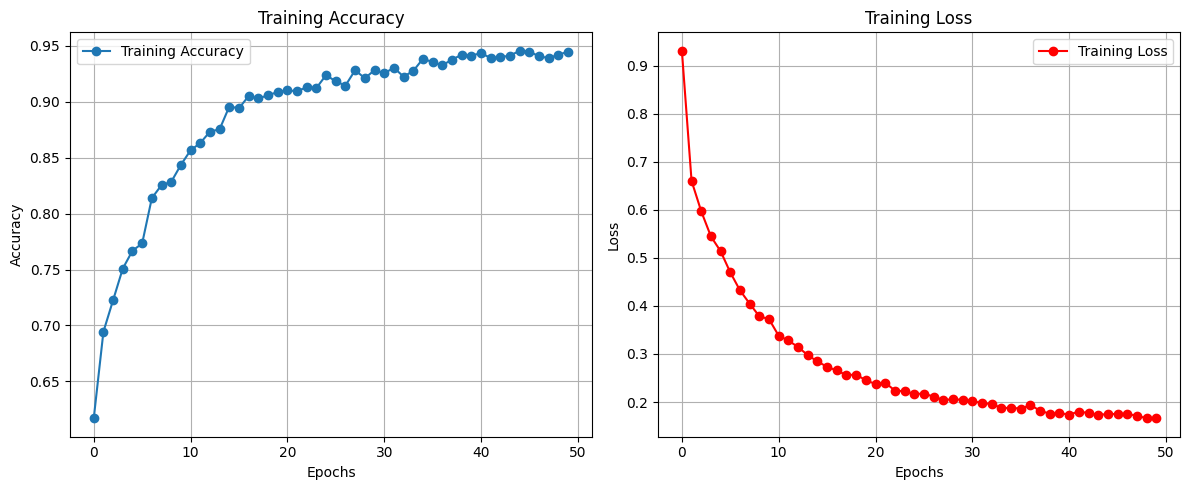

In [179]:
# Extract training accuracy and loss
TrainingAcc = history.history['accuracy']  # Corrected key
TrainingLoss = history.history['loss']

# Create figure with two subplots
plt.figure(figsize=(12, 5))

# Plot Training Accuracy
plt.subplot(1, 2, 1)
plt.plot(TrainingAcc, label="Training Accuracy", marker="o", linestyle="-")
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

# Plot Training Loss
plt.subplot(1, 2, 2)
plt.plot(TrainingLoss, label="Training Loss", marker="o", linestyle="-", color='red')
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

#### <b>Making Predictions</b>

> **y_pred_probs** stores the predicted probabilities for each class.

> **y_pred holds** the predicted class labels, which correspond to the class with the highest probability.

In [180]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

11/11 [==============================] - 0s 3ms/step


#### <b>Confusion Matrix</b>
The confusion matrix to show the number of correct and incorrect predictions for each class.



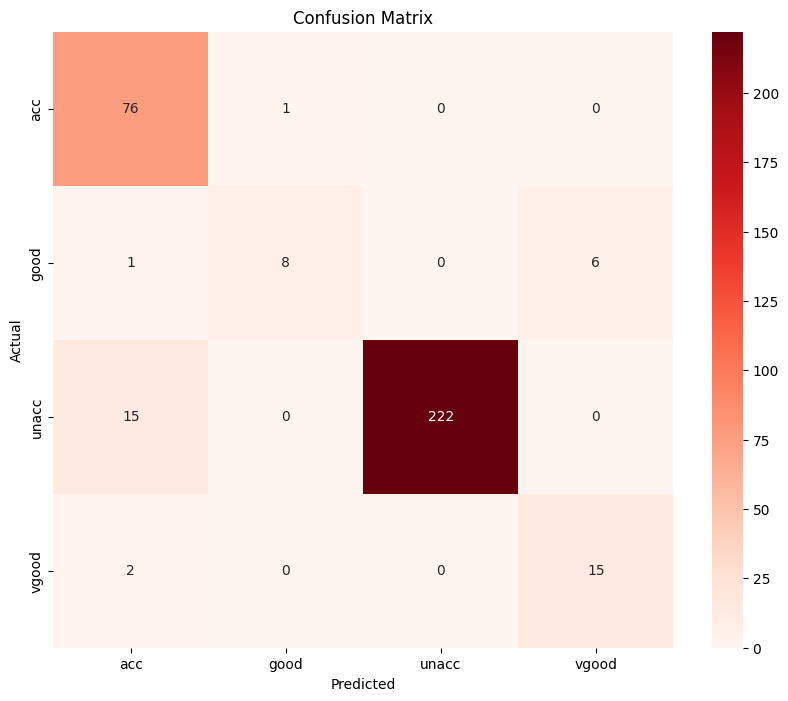

In [184]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()